# Time-Series Forecasting with SARIMA & Prophet
### Forecasting daily demand 30 days ahead

**RabTech Academy · Data Science with Python & R Internship · Task 5**
Author: Dheena Dhayalan P

| | |
|---|---|
| **Data** | RabTech Academy `daily-demand-series.csv`: daily demand for 1–30 June 2026, with `marketing_event` and `holiday` flags |
| **Train / test split** | Train on 1–23 June (23 days). **Hold out the last 7 days (24–30 June)** as the test split |
| **Metrics** | MAPE (mean absolute percentage error) and RMSE (root mean squared error) on the test split |
| **Final output** | 30-day forecast for 1–30 July 2026 with 95% prediction intervals |

**Pipeline**
1. Load data and explore it
2. Decompose into trend, seasonality and residual (classical and STL)
3. Stationarity: ADF (plus KPSS), differencing, ACF/PACF
4. Baseline forecasts
5. SARIMA: AIC grid search over (p,d,q)(P,D,Q)₇
6. SARIMAX with the event and holiday flags as exogenous regressors
7. Prophet with hyperparameter tuning on a validation window
8. Model comparison on the test split (MAPE, RMSE)
9. Residual diagnostics
10. Refit on all data and produce the 30-day forecast
11. Findings

In [1]:
import warnings, itertools, logging
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats
from prophet import Prophet
warnings.filterwarnings("ignore")   # after imports: statsmodels resets filters on import
for _name in ("cmdstanpy", "prophet"):  # silence Stan's per-fit progress messages
    logging.getLogger(_name).disabled = True

FIG =Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
COL = {"actual": "#2C3E50", "train": "#2C3E50", "test": "#E07B39", "sarima": "#2A8C82",
       "prophet": "#8E5BB5", "hw": "#3182BD", "base": "#95A5A6"}
SEASON = 7          # weekly seasonality in daily data
TEST_DAYS = 7
HORIZON = 30
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

def mape(a, f): return float(np.mean(np.abs((np.asarray(a) - np.asarray(f)) / np.asarray(a))) * 100)
def rmse(a, f): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(f)) ** 2)))
def fmt_dates(ax):
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

Importing plotly failed. Interactive plots will not work.


## 1. Load and explore the data

In [2]:
df = pd.read_csv("../data/raw/daily-demand-series.csv", parse_dates=["date"]).set_index("date").asfreq("D")
assert df.index.is_monotonic_increasing and df.isna().sum().sum() == 0
y = df["demand"]
print(f"{len(df)} daily observations: {df.index.min():%d %b %Y} to {df.index.max():%d %b %Y}, no gaps, no missing values")
df.assign(weekday=df.index.day_name()).head(8)

30 daily observations: 01 Jun 2026 to 30 Jun 2026, no gaps, no missing values


,demand,marketing_event,holiday,weekday
date,,,,
2026-06-01,118,0,0,Monday
2026-06-02,121,0,0,Tuesday
2026-06-03,125,0,0,Wednesday
2026-06-04,123,0,0,Thursday
2026-06-05,137,1,0,Friday
2026-06-06,151,1,0,Saturday
2026-06-07,143,0,1,Sunday
2026-06-08,126,0,0,Monday


In [3]:
by_dow = (df.assign(weekday=df.index.day_name(), dow=df.index.dayofweek)
            .groupby(["dow", "weekday"])
            .agg(mean_demand=("demand", "mean"), event_days=("marketing_event", "sum"),
                 holiday_days=("holiday", "sum")).droplevel(0))
by_dow

,mean_demand,event_days,holiday_days
weekday,,,
Monday,131.000,0,0
Tuesday,134.000,0,0
Wednesday,135.000,0,0
Thursday,136.500,0,0
Friday,150.000,4,0
Saturday,163.250,4,0
Sunday,149.750,0,4


The calendar is perfectly regular: **marketing events run every Friday and Saturday, and
every Sunday is a holiday.** Demand peaks on Saturday, so the series has a strong
**7-day seasonal cycle**.

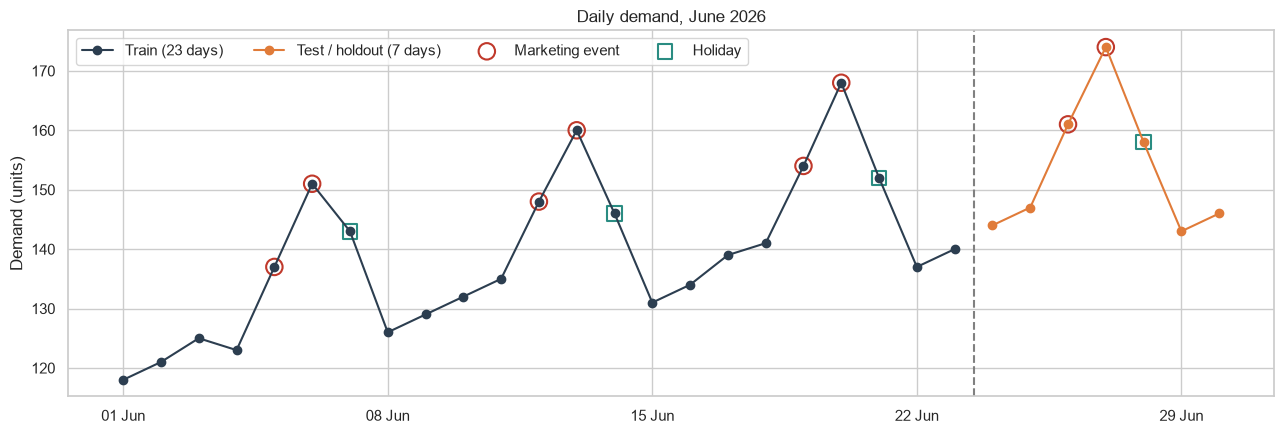

In [4]:
train, test = y.iloc[:-TEST_DAYS], y.iloc[-TEST_DAYS:]
X = df[["marketing_event", "holiday"]]
X_train, X_test = X.iloc[:-TEST_DAYS], X.iloc[-TEST_DAYS:]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(train, "o-", color=COL["train"], label=f"Train ({len(train)} days)")
ax.plot(test, "o-", color=COL["test"], label=f"Test / holdout ({len(test)} days)")
ev = df[df.marketing_event == 1]; ho = df[df.holiday == 1]
ax.scatter(ev.index, ev.demand, s=140, facecolors="none", edgecolors="#C0392B", lw=1.5, label="Marketing event")
ax.scatter(ho.index, ho.demand, marker="s", s=110, facecolors="none", edgecolors="#2A8C82", lw=1.5, label="Holiday")
ax.axvline(test.index[0] - pd.Timedelta(hours=12), color="grey", ls="--")
ax.set(title="Daily demand, June 2026", ylabel="Demand (units)"); fmt_dates(ax); ax.legend(ncol=4, loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "01_series.png", dpi=150); plt.show()

## 2. Decomposition: trend, seasonality and residual

The additive model is **yₜ = Trendₜ + Seasonalₜ + Residualₜ**, with a period of 7 days. We use
two methods:
- **Classical decomposition** (`seasonal_decompose`): a centred moving-average trend plus a
  fixed weekly pattern.
- **STL** (Seasonal-Trend decomposition using LOESS): more robust, and it gives a trend
  estimate at every date including the ends.

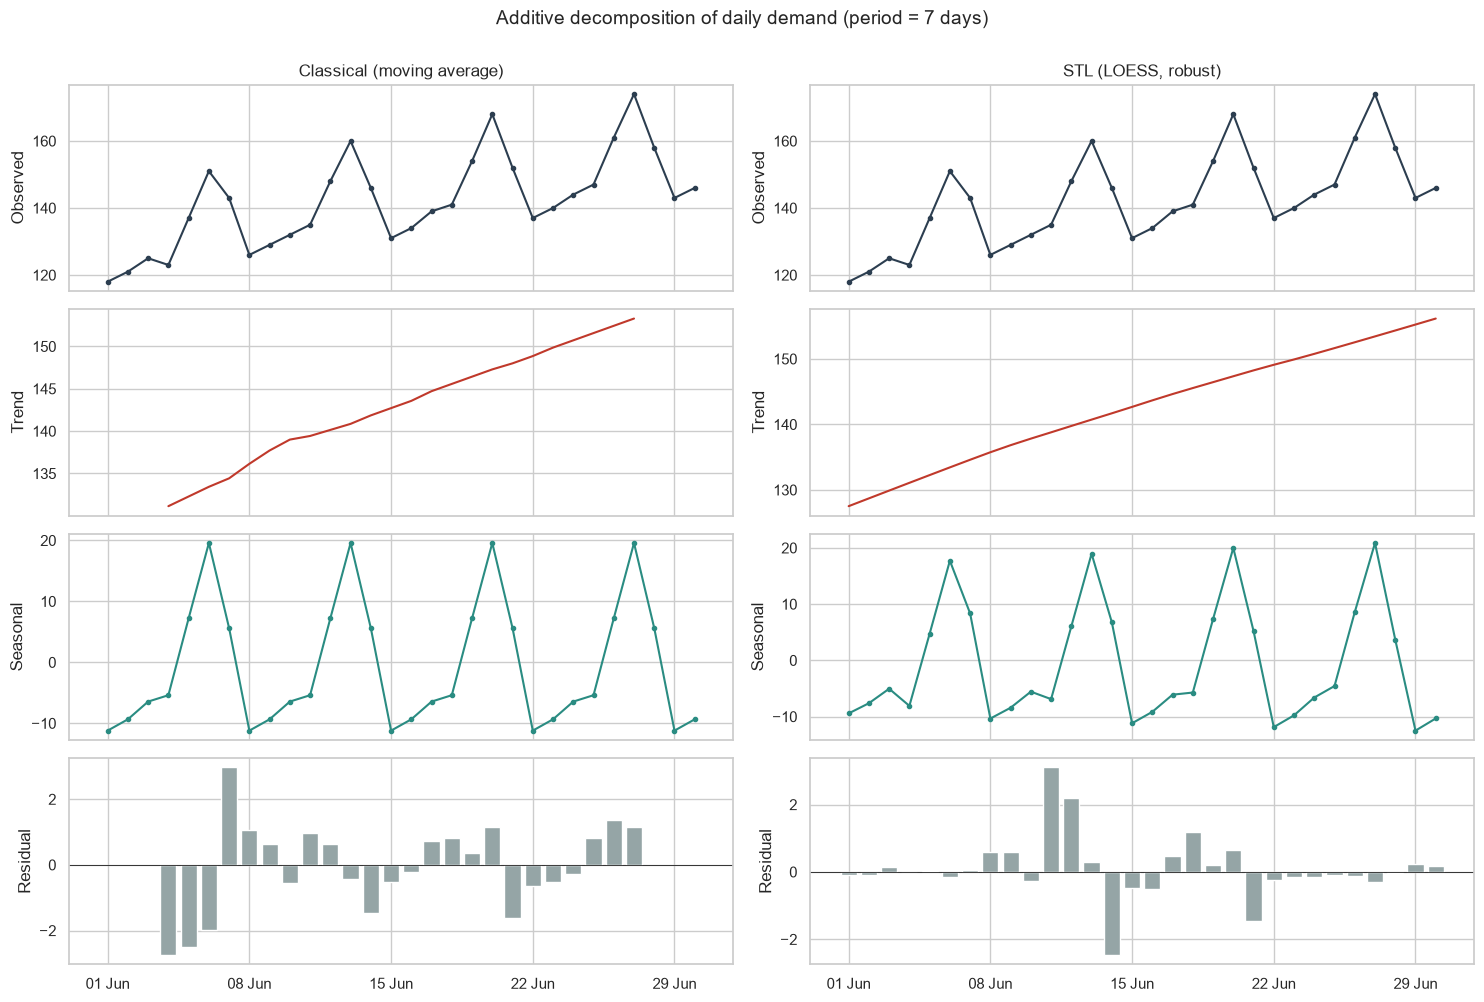

In [5]:
classical = seasonal_decompose(y, model="additive", period=SEASON)
stl = STL(y, period=SEASON, robust=True).fit()

fig, axes = plt.subplots(4, 2, figsize=(15, 10), sharex=True)
for j, (name, res) in enumerate([("Classical (moving average)", classical), ("STL (LOESS, robust)", stl)]):
    for i, (comp, label) in enumerate([(res.observed, "Observed"), (res.trend, "Trend"),
                                       (res.seasonal, "Seasonal"), (res.resid, "Residual")]):
        ax = axes[i, j]
        if label == "Residual":
            ax.bar(comp.index, comp.values, color="#95A5A6"); ax.axhline(0, color="k", lw=.6)
        else:
            ax.plot(comp, "o-" if label != "Trend" else "-", ms=3,
                    color={"Observed": COL["actual"], "Trend": "#C0392B", "Seasonal": COL["sarima"]}[label])
        ax.set_ylabel(label)
        if i == 0: ax.set_title(name)
    fmt_dates(axes[-1, j])
fig.suptitle("Additive decomposition of daily demand (period = 7 days)", y=1.0, fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "02_decomposition.png", dpi=150); plt.show()

In [6]:
seasonal_profile = (pd.Series(stl.seasonal.values, index=y.index.day_name())
                      .groupby(level=0).mean().reindex(
                      ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]))
trend_slope = np.polyfit(np.arange(len(y)), stl.trend.values, 1)[0]
var_y = np.var(y - y.mean())
strength_trend = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
strength_season = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
print(f"Trend slope:            {trend_slope:+.2f} units/day  (≈ {7*trend_slope:+.1f} per week)")
print(f"Strength of trend:      {strength_trend:.3f}   (0 = none, 1 = very strong)")
print(f"Strength of seasonality:{strength_season:.3f}")
print(f"Residual SD:            {stl.resid.std():.2f} units")
seasonal_profile.rename("STL weekly effect (units)").to_frame().T

Trend slope:            +0.97 units/day  (≈ +6.8 per week)
Strength of trend:      0.988   (0 = none, 1 = very strong)
Strength of seasonality:0.992
Residual SD:            0.95 units


date,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
STL weekly effect (units),-11.066,-9.063,-5.833,-6.319,6.670,19.384,6.008


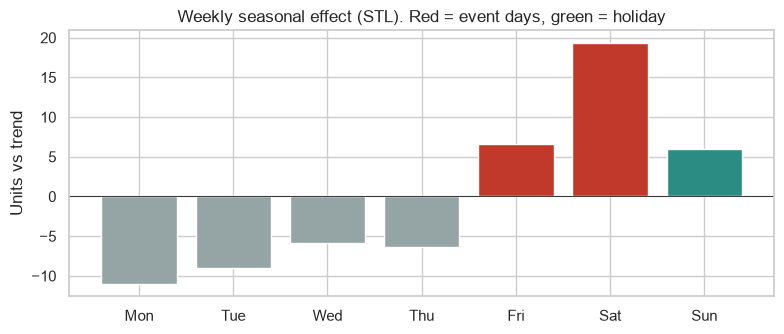

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
colors = ["#C0392B" if d in ("Friday", "Saturday") else "#2A8C82" if d == "Sunday" else "#95A5A6"
          for d in seasonal_profile.index]
ax.bar(seasonal_profile.index.str[:3], seasonal_profile.values, color=colors)
ax.axhline(0, color="k", lw=.6)
ax.set(title="Weekly seasonal effect (STL). Red = event days, green = holiday", ylabel="Units vs trend")
plt.tight_layout(); plt.savefig(FIG / "03_weekly_profile.png", dpi=150); plt.show()

**What the decomposition shows**
- **Trend:** a steady linear rise of **≈ +0.97 units/day (about +7 per week)**. The strength of
  trend is 0.99.
- **Seasonality:** a large, very stable weekly pattern (strength 0.99). Monday to Thursday sit
  6–11 units below the trend. **Saturday is +19**, Friday (event) +7 and Sunday (holiday) +6.
- **Residual:** an SD of only ≈ 0.95 units. Trend and seasonality explain almost all of the
  variation, so the series should be highly forecastable.

## 3. Stationarity: ADF test and differencing

ARIMA-type models need a **stationary** series (constant mean and variance over time). Two
tests have opposite null hypotheses, so they cross-check each other:

| Test | H₀ | H₁ | Conclude "stationary" when |
|---|---|---|---|
| **Augmented Dickey-Fuller (ADF)** | The series has a unit root (non-stationary) | The series is stationary | p < 0.05 |
| **KPSS** | The series is stationary | The series is non-stationary | p > 0.05 |

In [8]:
def stationarity(series, name):
    s = series.dropna()
    adf = adfuller(s, autolag="AIC", maxlag=5)
    kp = kpss(s, regression="c", nlags="auto")
    return {"series": name, "n": len(s), "ADF statistic": adf[0], "ADF p-value": adf[1],
            "KPSS p-value": kp[1],
            "verdict": "stationary" if (adf[1] < .05 and kp[1] > .05) else "NON-stationary"}

series_variants = {
    "Original yₜ": y,
    "First difference ∇yₜ (d=1)": y.diff(),
    "Seasonal difference ∇₇yₜ (D=1)": y.diff(SEASON),
    "Both ∇∇₇yₜ (d=1, D=1)": y.diff(SEASON).diff(),
}
adf_table = pd.DataFrame([stationarity(s, n) for n, s in series_variants.items()])
adf_table

,series,n,ADF statistic,ADF p-value,KPSS p-value,verdict
0,Original yₜ,30,-1.256,0.649,0.018,NON-stationary
1,First difference ∇yₜ (d=1),29,-8.194,0.000,0.100,stationary
2,Seasonal difference ∇₇yₜ (D=1),23,-2.851,0.051,0.100,NON-stationary
3,"Both ∇∇₇yₜ (d=1, D=1)",22,-5.191,0.000,0.100,stationary


*KPSS p-values are capped at 0.1 by its look-up table, so "0.1" means "> 0.1".*

**Decision**
- The **original series is non-stationary** (ADF p ≈ 0.65, so we can't reject a unit root, and
  KPSS rejects stationarity). This is expected given the trend.
- **One regular difference (d = 1) is enough to make it stationary.** A seasonal difference on
  its own is borderline (ADF p ≈ 0.051).
- Taking both differences is also stationary. Whether to add D = 1 is left to the AIC model
  selection in §5.

*Caveat:* with only 22–30 observations the ADF test has low power, which is why KPSS and the
plots are used as well.

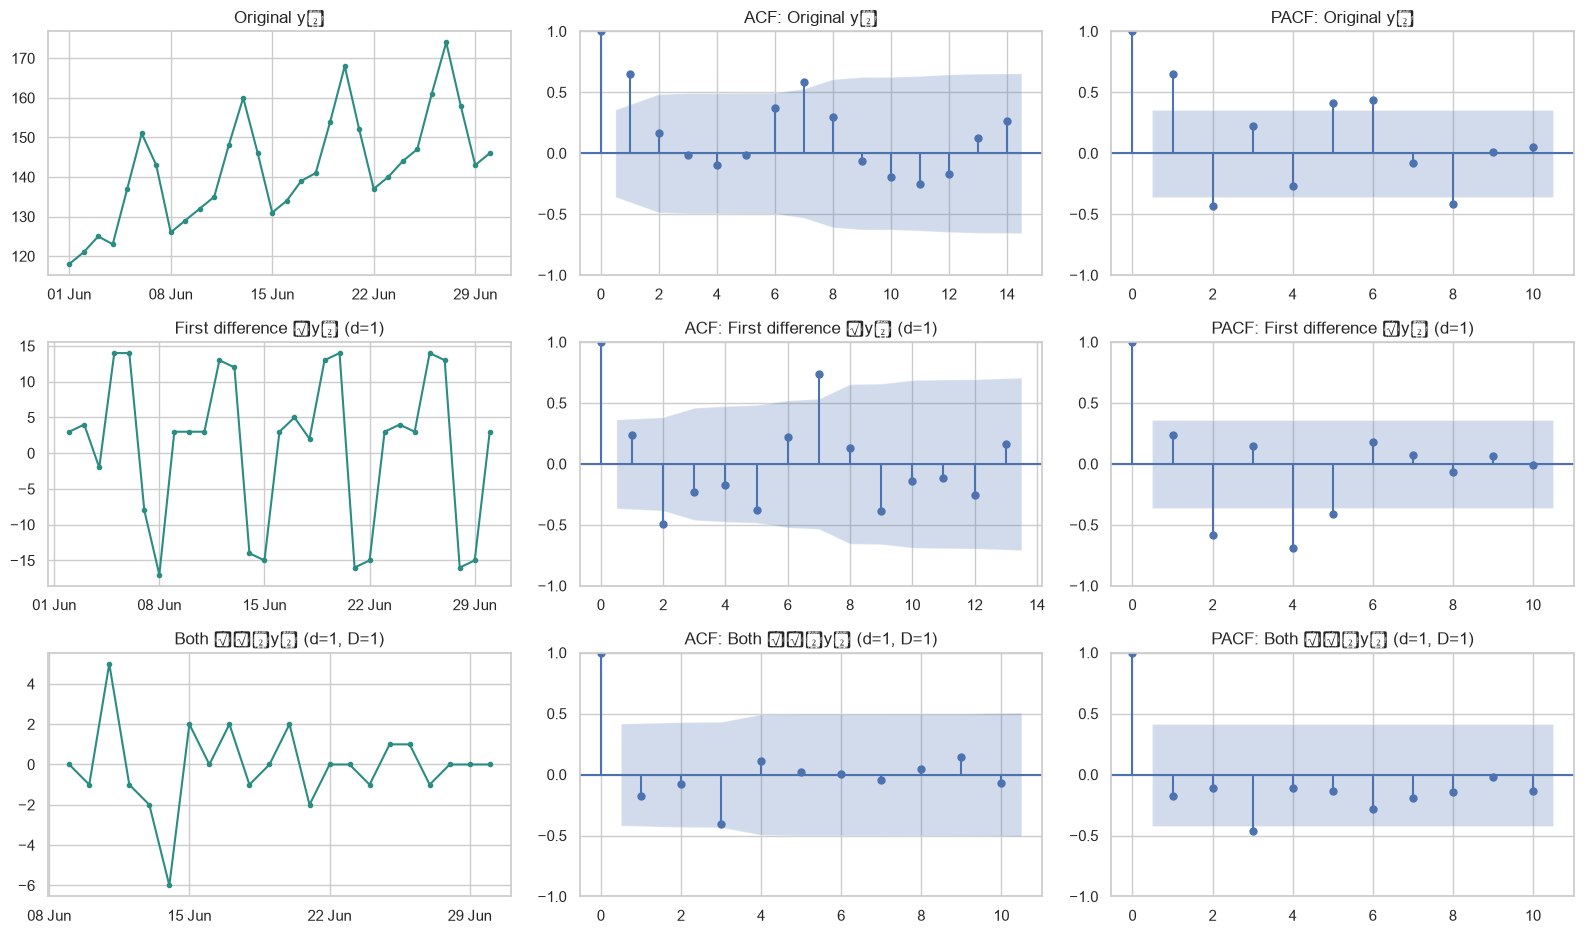

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(16, 9.5))
for row, (name, s) in enumerate(list(series_variants.items())[:2] + [list(series_variants.items())[3]]):
    s = s.dropna()
    axes[row, 0].plot(s, "o-", ms=3, color=COL["sarima"]); axes[row, 0].set_title(name); fmt_dates(axes[row, 0])
    plot_acf(s, lags=min(14, len(s) // 2 - 1), ax=axes[row, 1], title=f"ACF: {name}")
    plot_pacf(s, lags=min(10, len(s) // 2 - 1), ax=axes[row, 2], title=f"PACF: {name}", method="ywm")
plt.tight_layout(); plt.savefig(FIG / "04_differencing_acf_pacf.png", dpi=150); plt.show()

The **ACF of the original series** decays slowly, the classic sign of a trend. After first
differencing, the ACF shows **spikes at lags 7 and 14**, which is the weekly seasonality that a
seasonal (P, D, Q)₇ term must capture. After both differences, almost no significant
autocorrelation is left.

## 4. Baselines

A model is only useful if it beats simple rules. Every baseline below forecasts the 7-day test
window using **training data only**:
- **Naive:** repeat the last observed value.
- **Seasonal naive:** repeat the value from the same weekday last week.
- **Seasonal naive + drift:** the same weekday last week, plus that weekday's week-on-week change.

In [10]:
forecasts = {}
forecasts["Naive"] = pd.Series(train.iloc[-1], index=test.index)
forecasts["Seasonal naive"] = pd.Series(train.iloc[-SEASON:].values, index=test.index)
forecasts["Seasonal naive + drift"] = pd.Series(
    train.iloc[-SEASON:].values + (train.iloc[-SEASON:].values - train.iloc[-2 * SEASON:-SEASON].values),
    index=test.index)
pd.DataFrame({k: {"MAPE %": mape(test, f), "RMSE": rmse(test, f)} for k, f in forecasts.items()}).T

,MAPE %,RMSE
Naive,8.246,17.034
Seasonal naive,3.922,6.024
Seasonal naive + drift,0.451,1.134


## 5. SARIMA: hyperparameter selection by AIC

**SARIMA(p, d, q)(P, D, Q)ₛ** combines:
- AR(p): dependence on past values
- I(d): differencing
- MA(q): dependence on past shocks
- the seasonal versions of each, (P, D, Q), at lag s = 7

We search p ∈ {0,1,2}, d ∈ {0,1}, q ∈ {0,1}, P, D, Q ∈ {0,1}, plus a trend term where the
differencing allows one. Each model is fit **on the training data only** and ranked by **AIC**
(Akaike Information Criterion: lower is better, and it penalises extra parameters). The test
week is never used for selection.

In [11]:
grid = []
for p, d, q, P, D, Q in itertools.product([0, 1, 2], [0, 1], [0, 1], [0, 1], [0, 1], [0, 1]):
    trends = ["n", "c", "t"] if d + D == 0 else (["n", "c"] if d + D == 1 else ["n"])
    for tr in trends:
        try:
            fit = SARIMAX(train, order=(p, d, q), seasonal_order=(P, D, Q, SEASON), trend=tr).fit(disp=False)
            grid.append({"order": (p, d, q), "seasonal_order": (P, D, Q, SEASON), "trend": tr,
                         "AIC": fit.aic, "BIC": fit.bic, "n_params": len(fit.params)})
        except Exception:
            pass
grid = pd.DataFrame(grid).sort_values("AIC").reset_index(drop=True)
print(f"Models fitted: {len(grid)}")
grid.head(10)

Models fitted: 192


,order,seasonal_order,trend,AIC,BIC,n_params
0,"(0, 1, 0)","(0, 1, 0, 7)",n,70.410,71.118,1
1,"(1, 1, 1)","(0, 1, 0, 7)",n,71.579,73.703,3
2,"(0, 1, 1)","(0, 1, 0, 7)",n,71.788,73.204,2
3,"(1, 1, 0)","(0, 1, 0, 7)",n,72.013,73.430,2
4,"(0, 1, 0)","(0, 1, 1, 7)",n,72.405,73.821,2
5,"(0, 1, 0)","(1, 1, 0, 7)",n,72.405,73.821,2
6,"(1, 0, 0)","(0, 1, 0, 7)",c,73.181,75.499,3
7,"(2, 1, 1)","(0, 1, 0, 7)",n,73.437,76.269,4
8,"(1, 1, 1)","(0, 1, 1, 7)",n,73.531,76.363,4
9,"(1, 1, 1)","(1, 1, 0, 7)",n,73.531,76.364,4


In [12]:
best = grid.iloc[0]
sarima = SARIMAX(train, order=best.order, seasonal_order=best.seasonal_order, trend=best.trend).fit(disp=False)
fc = sarima.get_forecast(TEST_DAYS)
forecasts["SARIMA"] = fc.predicted_mean
sarima_ci = fc.conf_int(alpha=0.05)
print(f"Selected: SARIMA{best.order}x{best.seasonal_order}  trend='{best.trend}'  AIC={best.AIC:.1f}")
print(sarima.summary().tables[1])

Selected: SARIMA(0, 1, 0)x(0, 1, 0, 7)  trend='n'  AIC=70.4
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         5.6000      1.602      3.497      0.000       2.461       8.739


**Selected model: SARIMA(0,1,0)(0,1,0)₇**, which means one regular and one seasonal difference
and no AR or MA terms. Written out:

  yₜ = yₜ₋₁ + (yₜ₋₇ − yₜ₋₈) + εₜ

In words: *today = yesterday + the change seen between the same two weekdays last week.* This
is the simplest model that fully captures both a linear trend and a fixed weekly pattern. AIC
prefers it over larger models because the extra AR and MA terms don't improve the fit enough
to justify their parameters. The differencing that AIC chose (d = 1, D = 1) agrees with the
stationarity analysis in §3.

## 6. SARIMAX: adding event and holiday flags

The flags are known in advance (events are planned), so they can be used as **exogenous
regressors**. ARIMA(p, d, q) + `marketing_event` + `holiday` is searched the same way, with
selection by AIC on the training data.

In [13]:
xgrid = []
for p, d, q in itertools.product([0, 1, 2], [0, 1], [0, 1, 2]):
    for tr in (["c", "t", "ct"] if d == 0 else ["n", "c"]):
        try:
            fit = SARIMAX(train, exog=X_train, order=(p, d, q), trend=tr).fit(disp=False)
            xgrid.append({"order": (p, d, q), "trend": tr, "AIC": fit.aic})
        except Exception:
            pass
xgrid = pd.DataFrame(xgrid).sort_values("AIC").reset_index(drop=True)
xb = xgrid.iloc[0]
sarimax = SARIMAX(train, exog=X_train, order=xb.order, trend=xb.trend).fit(disp=False)
forecasts["SARIMAX (event + holiday)"] = sarimax.get_forecast(TEST_DAYS, exog=X_test).predicted_mean
print(f"Selected: ARIMA{xb.order} + exog, trend='{xb.trend}', AIC={xb.AIC:.1f}")
sarimax.params[["marketing_event", "holiday"]].rename("coefficient (units)").to_frame().T

Selected: ARIMA(2, 1, 1) + exog, trend='c', AIC=134.9


,marketing_event,holiday
coefficient (units),21.897,10.642


The flags have large, sensible coefficients. But **a single `marketing_event` coefficient
can't tell Friday from Saturday**, and Saturday demand is consistently higher. The AIC of this
model is also much worse than the seasonal model's. Because the flags line up exactly with
weekdays, the seasonal term already carries all of their information, and more precisely.

## 7. Prophet: tuning on a validation window

Prophet fits an additive model: piecewise-linear trend + Fourier weekly seasonality (+ optional
regressors). Two key hyperparameters are tuned:
- `changepoint_prior_scale`: how flexible the trend is
- `seasonality_prior_scale`: how strong the seasonality can be

To keep the test week untouched, tuning uses an **inner split**: fit on 1–16 June and validate
on 17–23 June. The best setting is then refit on the full training set (1–23 June).

In [14]:
def to_prophet(series, exog=None):
    out = series.rename_axis("ds").reset_index().rename(columns={series.name: "y"})
    if exog is not None:
        out = pd.concat([out, exog.reset_index(drop=True)], axis=1)
    return out

def make_prophet(cps, sps, regressors=False):
    m = Prophet(yearly_seasonality=False, daily_seasonality=False, weekly_seasonality=not regressors,
                changepoint_prior_scale=cps, seasonality_prior_scale=sps)
    if regressors:
        for c in ["marketing_event", "holiday"]:
            m.add_regressor(c)
    return m

inner_tr, inner_val = train.iloc[:-SEASON], train.iloc[-SEASON:]
Xi_tr, Xi_val = X_train.iloc[:-SEASON], X_train.iloc[-SEASON:]
tuning = []
for regressors in [False, True]:
    for cps in [0.001, 0.01, 0.05, 0.1, 0.5]:
        for sps in [0.1, 1.0, 10.0]:
            m = make_prophet(cps, sps, regressors).fit(to_prophet(inner_tr, Xi_tr if regressors else None))
            fut = to_prophet(inner_val, Xi_val if regressors else None).drop(columns="y")
            pred = m.predict(fut)["yhat"].values
            tuning.append({"variant": "regressors" if regressors else "weekly seasonality",
                           "changepoint_prior_scale": cps, "seasonality_prior_scale": sps,
                           "validation MAPE %": mape(inner_val, pred), "validation RMSE": rmse(inner_val, pred)})
tuning = pd.DataFrame(tuning).sort_values("validation RMSE").reset_index(drop=True)
tuning.head(8)

,variant,changepoint_prior_scale,seasonality_prior_scale,validation MAPE %,validation RMSE
0,weekly seasonality,0.100,0.100,0.808,1.400
1,weekly seasonality,0.500,0.100,1.035,1.726
2,weekly seasonality,0.001,1.000,1.178,1.978
3,weekly seasonality,0.001,10.000,1.174,1.980
4,weekly seasonality,0.010,1.000,1.171,1.985
5,weekly seasonality,0.010,10.000,1.173,1.989
6,weekly seasonality,0.010,0.100,1.184,2.011
7,weekly seasonality,0.001,0.100,1.185,2.021


In [15]:
bp = tuning.iloc[0]
use_reg = bp.variant == "regressors"
prophet = make_prophet(bp.changepoint_prior_scale, bp.seasonality_prior_scale, use_reg).fit(
    to_prophet(train, X_train if use_reg else None))
p_fc = prophet.predict(to_prophet(test, X_test if use_reg else None).drop(columns="y"))
forecasts["Prophet (tuned)"] = pd.Series(p_fc["yhat"].values, index=test.index)
prophet_ci = p_fc[["yhat_lower", "yhat_upper"]].set_index(test.index)
print(f"Selected Prophet: {bp.variant}, changepoint_prior_scale={bp.changepoint_prior_scale}, "
      f"seasonality_prior_scale={bp.seasonality_prior_scale}")

Selected Prophet: weekly seasonality, changepoint_prior_scale=0.1, seasonality_prior_scale=0.1


For reference, **Holt-Winters additive exponential smoothing** (level + trend + 7-day season)
is added as another classical benchmark.

In [16]:
hw = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=SEASON).fit()
forecasts["Holt-Winters"] = hw.forecast(TEST_DAYS)

## 8. Model comparison on the 7-day test split

In [17]:
results = (pd.DataFrame({k: {"MAPE %": mape(test, f), "RMSE": rmse(test, f),
                             "max abs error": float(np.max(np.abs(test - f)))}
                         for k, f in forecasts.items()}).T.sort_values("RMSE"))
results

,MAPE %,RMSE,max abs error
SARIMA,0.188,0.535,1.000
Seasonal naive + drift,0.451,1.134,2.000
Prophet (tuned),0.743,1.388,2.479
Holt-Winters,0.784,1.587,2.651
SARIMAX (event + holiday),2.357,3.839,5.185
Seasonal naive,3.922,6.024,7.000
Naive,8.246,17.034,34.000


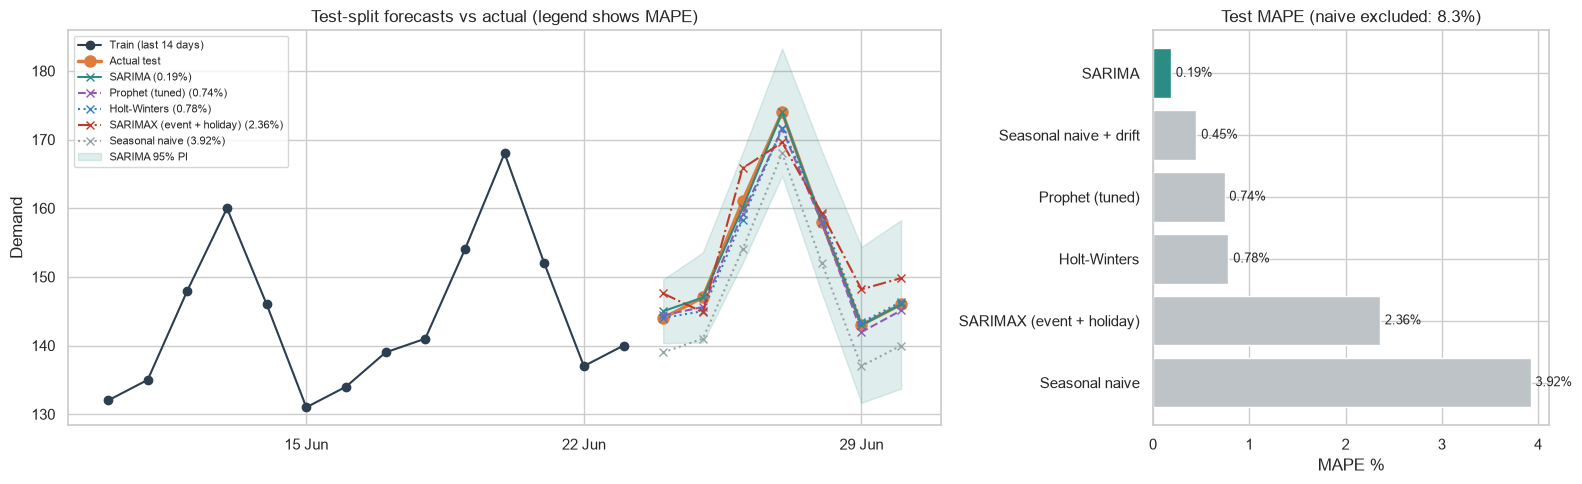

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
ax.plot(train.iloc[-14:], "o-", color=COL["train"], label="Train (last 14 days)")
ax.plot(test, "o-", color=COL["test"], lw=2.5, ms=8, label="Actual test")
for name, c, ls in [("SARIMA", COL["sarima"], "-"), ("Prophet (tuned)", COL["prophet"], "--"),
                    ("Holt-Winters", COL["hw"], ":"), ("SARIMAX (event + holiday)", "#C0392B", "-."),
                    ("Seasonal naive", COL["base"], ":")]:
    ax.plot(forecasts[name], ls, color=c, marker="x", label=f"{name} ({mape(test, forecasts[name]):.2f}%)")
ax.fill_between(test.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1], color=COL["sarima"], alpha=.15,
                label="SARIMA 95% PI")
ax.set(title="Test-split forecasts vs actual (legend shows MAPE)", ylabel="Demand"); fmt_dates(ax)
ax.legend(fontsize=8, loc="upper left")
r = results.drop("Naive")
axes[1].barh(r.index, r["MAPE %"], color=[COL["sarima"] if i == "SARIMA" else "#BDC3C7" for i in r.index])
for i, v in enumerate(r["MAPE %"]): axes[1].text(v + .05, i, f"{v:.2f}%", va="center", fontsize=9)
axes[1].invert_yaxis(); axes[1].set(title="Test MAPE (naive excluded: 8.3%)", xlabel="MAPE %")
plt.tight_layout(); plt.savefig(FIG / "05_test_comparison.png", dpi=150); plt.show()

**Result on the held-out week**
- **SARIMA is the most accurate: MAPE 0.19%, RMSE 0.53, and never more than 1 unit off on any
  day.** That's about 44× better than the naive forecast (8.2%).
- The second best is the simple **seasonal naive + drift** rule (0.45%). This makes sense, because
  the selected SARIMA is almost the same idea written as a formal statistical model. The main
  difference is that SARIMA also uses the most recent day, and it provides prediction intervals.
- **Tuned Prophet (0.74%)** and **Holt-Winters (0.78%)** are also very good, but slightly smoother
  than the data's sharp weekend peaks.
- **SARIMAX with flags (2.36%)** is the weakest model that uses information correctly. It gets the
  Friday vs Saturday level wrong.

## 9. Residual diagnostics (selected SARIMA)

A good model leaves **white-noise residuals**: no autocorrelation and roughly normal.
- **Ljung-Box test.** H₀: the residuals are uncorrelated up to lag *k*. We want p > 0.05.
- **Shapiro-Wilk test.** H₀: the residuals are normal.

The first d + s·D = 8 residuals are start-up artefacts of differencing, so they are dropped.

In [19]:
resid = sarima.resid.iloc[1 + SEASON:]
lb = acorr_ljungbox(resid, lags=[3, 7], return_df=True)
print(f"Residual mean = {resid.mean():.3f}, SD = {resid.std():.3f}, Shapiro-Wilk p = {stats.shapiro(resid).pvalue:.3f}")
lb.rename(columns={"lb_stat": "Ljung-Box Q", "lb_pvalue": "p-value"})

Residual mean = -0.133, SD = 2.446, Shapiro-Wilk p = 0.185


,Ljung-Box Q,p-value
3,5.118,0.163
7,5.795,0.564


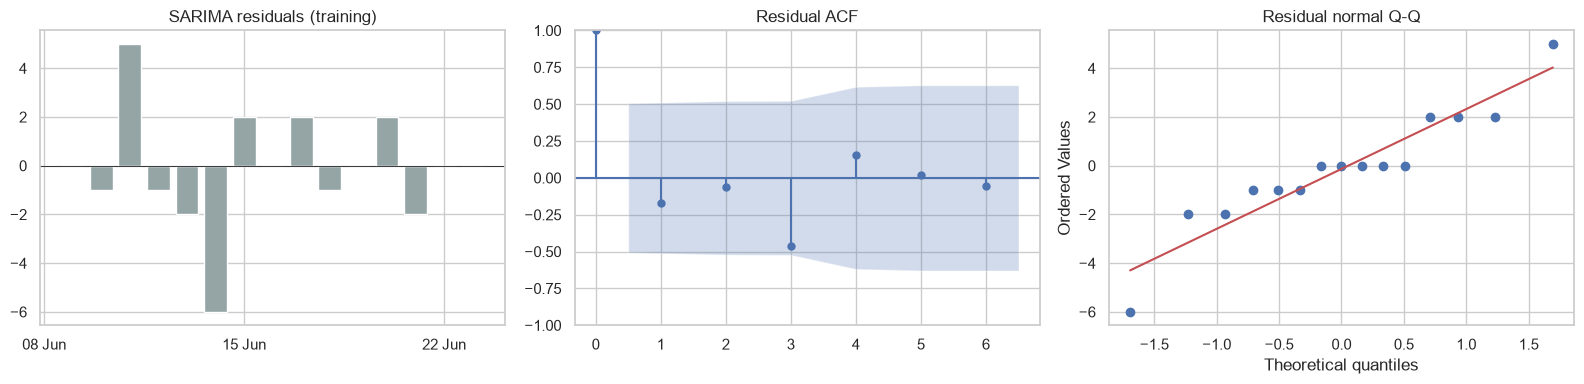

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(resid.index, resid.values, color="#95A5A6"); axes[0].axhline(0, color="k", lw=.6)
axes[0].set_title("SARIMA residuals (training)"); fmt_dates(axes[0])
plot_acf(resid, lags=min(7, len(resid) // 2 - 1), ax=axes[1], title="Residual ACF")
stats.probplot(resid, dist="norm", plot=axes[2]); axes[2].set_title("Residual normal Q-Q")
plt.tight_layout(); plt.savefig(FIG / "06_residual_diagnostics.png", dpi=150); plt.show()

**Result:** the Ljung-Box p-values are above 0.05 at lags 3 and 7, so no autocorrelation is left,
and the Shapiro-Wilk test does not reject normality. **The residuals behave like white noise.**
The model has captured all of the structure in the series.

## 10. Final model: refit on all 30 days and forecast 1–30 July 2026

The model is now refit on **all 30 days**, keeping the specification that AIC selected on the
training data, and forecast 30 days ahead. Prophet (refit on all data with its tuned
hyperparameters) is shown alongside as a second opinion.

**Assumption:** the weekly pattern continues, meaning events on Fridays and Saturdays and
holidays on Sundays. If July's calendar differs (for example a mid-week campaign), the forecast
for those days should be adjusted.

In [21]:
final = SARIMAX(y, order=best.order, seasonal_order=best.seasonal_order, trend=best.trend).fit(disp=False)
f_final = final.get_forecast(HORIZON)
future_idx = pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=HORIZON, freq="D")
ci80 = f_final.conf_int(alpha=0.20); ci95 = f_final.conf_int(alpha=0.05)
forecast_table = pd.DataFrame({
    "weekday": future_idx.day_name(),
    "forecast": f_final.predicted_mean.values,
    "lower 95%": ci95.iloc[:, 0].values, "upper 95%": ci95.iloc[:, 1].values,
}, index=future_idx.rename("date"))

future_X = pd.DataFrame({"marketing_event": future_idx.dayofweek.isin([4, 5]).astype(int),
                         "holiday": (future_idx.dayofweek == 6).astype(int)}, index=future_idx)
prophet_full = make_prophet(bp.changepoint_prior_scale, bp.seasonality_prior_scale, use_reg).fit(
    to_prophet(y, X if use_reg else None))
pf = prophet_full.predict(pd.DataFrame({"ds": future_idx, **({c: future_X[c].values for c in future_X} if use_reg else {})}))
forecast_table["Prophet"] = pf["yhat"].values
forecast_table.to_csv("../reports/forecast_july_2026.csv", float_format="%.1f")
forecast_table.round(1)

,weekday,forecast,lower 95%,upper 95%,Prophet
date,,,,,
2026-07-01,Wednesday,150.000,146.100,153.900,150.700
2026-07-02,Thursday,153.000,147.500,158.500,152.500
2026-07-03,Friday,167.000,160.200,173.800,166.300
2026-07-04,Saturday,180.000,172.200,187.800,178.900
2026-07-05,Sunday,164.000,155.200,172.800,164.600
2026-07-06,Monday,149.000,139.400,158.600,149.000
2026-07-07,Tuesday,152.000,141.600,162.400,152.300
2026-07-08,Wednesday,156.000,143.000,169.000,156.700
2026-07-09,Thursday,159.000,143.800,174.200,158.500


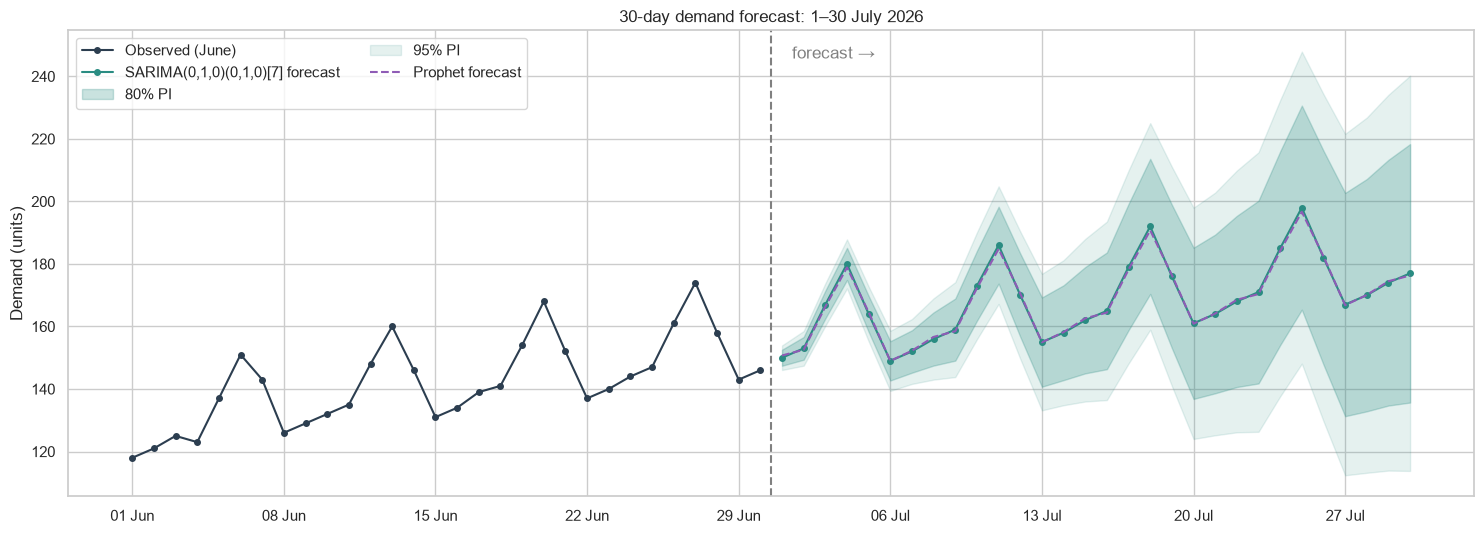

In [22]:
fig, ax = plt.subplots(figsize=(15, 5.5))
ax.plot(y, "o-", color=COL["actual"], ms=4, label="Observed (June)")
ax.plot(forecast_table["forecast"], "o-", color=COL["sarima"], ms=4, label="SARIMA(0,1,0)(0,1,0)[7] forecast")
ax.fill_between(future_idx, ci80.iloc[:, 0], ci80.iloc[:, 1], color=COL["sarima"], alpha=.25, label="80% PI")
ax.fill_between(future_idx, ci95.iloc[:, 0], ci95.iloc[:, 1], color=COL["sarima"], alpha=.12, label="95% PI")
ax.plot(forecast_table["Prophet"], "--", color=COL["prophet"], label="Prophet forecast")
ax.axvline(future_idx[0] - pd.Timedelta(hours=12), color="grey", ls="--")
ax.text(future_idx[0], ax.get_ylim()[1] * .98, "  forecast →", va="top", color="grey")
ax.set(title="30-day demand forecast: 1–30 July 2026", ylabel="Demand (units)"); fmt_dates(ax)
ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.savefig(FIG / "07_forecast_30_days.png", dpi=150); plt.show()

In [23]:
weekly = forecast_table.assign(week=forecast_table.index.isocalendar().week.values) \
                       .groupby("week").agg(days=("forecast", "size"), total_forecast=("forecast", "sum"),
                                            Prophet_total=("Prophet", "sum"))
june_total = y.sum()
print(f"June actual total: {june_total:,}   |   July SARIMA forecast total: {forecast_table.forecast.sum():,.0f} "
      f"({forecast_table.forecast.sum() / june_total - 1:+.1%})")
weekly.round(0)

June actual total: 4,263   |   July SARIMA forecast total: 5,063 (+18.8%)


,days,total_forecast,Prophet_total
week,,,
27,5,814.000,813.000
28,7,"1,145.000","1,144.000"
29,7,"1,187.000","1,186.000"
30,7,"1,229.000","1,227.000"
31,4,688.000,688.000


## 11. Findings

| Step | Result |
|---|---|
| **Decomposition** | Steady **linear upward trend** (+0.97 units/day, about +7/week) plus a strong, stable **weekly cycle**: Saturday +19, Fri/Sun +6–7, weekdays −6 to −11. Residual SD ≈ 0.95 units |
| **Stationarity** | Original series **non-stationary** (ADF p ≈ 0.65). **Stationary after first differencing** (ADF p < 0.001, KPSS agrees) |
| **Hyperparameter selection** | SARIMA: AIC grid over the models in §5, fit on training data only, **best = SARIMA(0,1,0)(0,1,0)₇**. Prophet: tuned on an inner validation week |
| **Test accuracy (24–30 June)** | **SARIMA: MAPE 0.19%, RMSE 0.53 units** (max error 1 unit), the best model and about 44× better than naive (8.2%). Prophet 0.74%, Holt-Winters 0.78% |
| **Exogenous flags** | SARIMAX with event/holiday flags is *worse* (MAPE 2.36%). The flags can't separate Friday from Saturday, and the seasonal term already contains their information |
| **Diagnostics** | Ljung-Box p = 0.16 (lag 3) and 0.56 (lag 7), Shapiro p = 0.19: the residuals are white noise |
| **30-day forecast** | From 150 units (Wed 1 Jul) to a weekly Saturday peak of ≈ 180 → 198. **July total ≈ 5,063 units (+18.8% vs June).** SARIMA and Prophet agree within about 1% each week. The 95% intervals widen from ±4 units on day 1 to about ±60 by day 30 |

**Conclusions**
1. Demand is driven by a **linear growth trend plus a fixed weekly calendar effect**. A very
   simple seasonal ARIMA captures both almost perfectly.
2. **Simple, well-specified models win on short, regular series.** More flexible models
   (Prophet, SARIMAX) add parameters but no accuracy here.
3. Saturdays are the peak, so stock and staffing should be planned around them.

**Limitations: please read**
- **Only 30 observations.** The test split is a single week, and the ADF test has low power at
  this sample size.
- **The near-perfect test accuracy reflects how regular the series is**, which looks synthetic or
  idealised. Real demand data would be noisier, and errors would be larger.
- **The 30-day forecast extrapolates a linear trend** four weeks beyond the data and assumes the
  same weekly event calendar. Treat the widening 95% intervals as the honest range of
  uncertainty, and re-train the model as July data arrives.